# Data Exploration: Pima Indians Diabetes

In [57]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)


In [2]:
# Load the data (path is relative to this notebook in assets/)
df = pd.read_csv("../data/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

Rows: 768, Columns: 9


In [4]:
n_before = len(df)
df = df.dropna(subset=["Outcome"])
print(f"Removed {n_before - len(df)} rows with missing Outcome, {len(df)} rows remain")


Removed 0 rows with missing Outcome, 768 rows remain


In [8]:
# 1st split: 20% of all rows for training, 80% left over
df_train, df_other = train_test_split(
    df,
    train_size=0.2,
    stratify=df["Outcome"],
    random_state=42,
)

# 2nd split: 10% of all rows for testing (0.125 * 80% = 10%), the remaining 70% is df_rest
df_test, df_rest = train_test_split(
    df_other,
    train_size=0.125,
    stratify=df_other["Outcome"],
    random_state=42,
)

print(df_train.shape, df_test.shape, df_rest.shape)

(153, 9) (76, 9) (539, 9)


In [9]:
# df_rest stands in for new patients: drop the target so only the features are left
df_rest = df_rest.drop(columns=["Outcome"])

print(df_rest.shape)


(539, 8)


We have three hyptothesis so far:

1. BMI
2. Age 
3. Glucose concentration

We need some more exploration to figure out (without model training):

- is there a correlation between each of the parameter and the desease? 
- how strong is the correlation?

For this purpose we need to create some exploratory graphics,
then look upon them and decide, which of them are most are most relevant.

In [21]:
features = ["BMI", "Age", "Glucose"]

# Columns where 0 is physically impossible and stands for a missing measurement
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
# eda is a copy of the training data for exploration and visualization
eda = df_train.copy()
eda[zero_as_missing] = eda[zero_as_missing].replace(0, np.nan)

n_before = len(eda)
eda = eda.dropna(subset=features)   # only the columns your hypotheses use
print(f"Dropped {n_before - len(eda)} rows, {len(eda)} remain")

eda["Diabetes"] = eda["Outcome"].map({0: "No", 1: "Yes"})

Dropped 3 rows, 150 remain


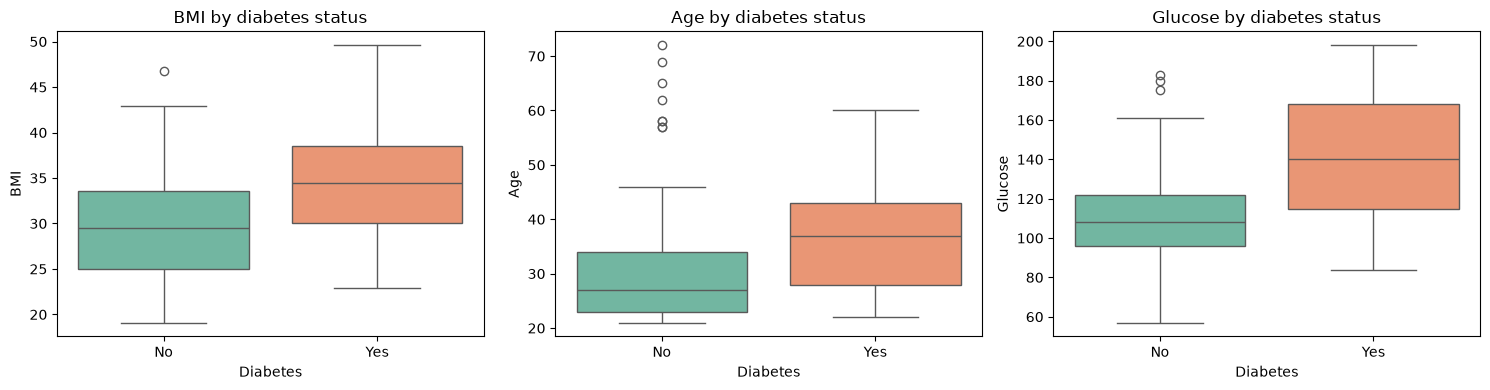

In [22]:
#If the boxes for "Yes" sit clearly higher than those for "No", that feature is related to diabetes.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
    sns.boxplot(data=eda, x="Diabetes", y=col, hue="Diabetes",
                palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col} by diabetes status")
plt.tight_layout()
plt.show()

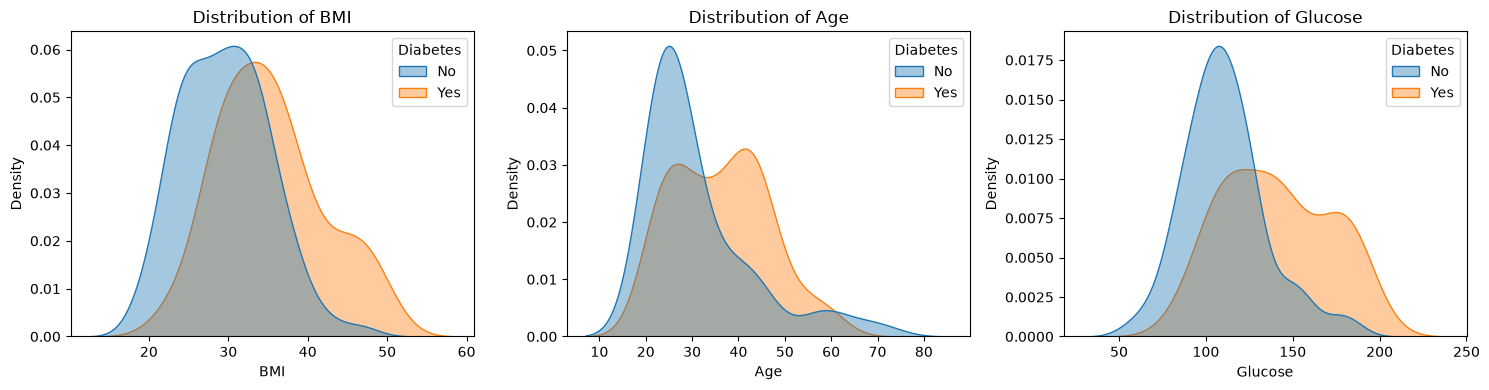

In [23]:
#Density plots can also be used to visualize the distribution of a feature for each class. If the distributions are clearly separated, that feature is related to diabetes.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
    sns.kdeplot(data=eda, x=col, hue="Diabetes", common_norm=False,
                fill=True, alpha=0.4, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

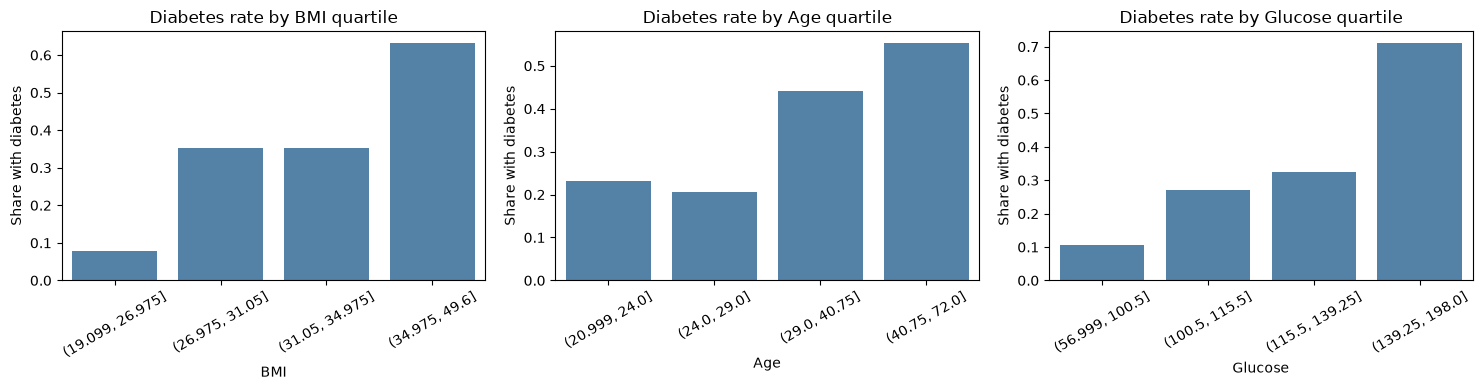

In [24]:
# This plot tests the "the more …, the more …" form of a hypothesis directly
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
    rate = (eda.groupby(pd.qcut(eda[col], q=4), observed=True)["Outcome"]
               .mean()
               .reset_index())
    rate[col] = rate[col].astype(str)
    sns.barplot(data=rate, x=col, y="Outcome", color="steelblue", ax=ax)
    ax.set_ylabel("Share with diabetes")
    ax.set_title(f"Diabetes rate by {col} quartile")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


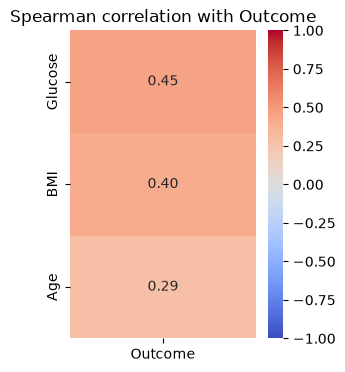

In [25]:
# Correlation matrix
corr_outcome = (
    eda[features + ["Outcome"]]
    .corr(method="spearman")[["Outcome"]]   # keep only the Outcome column
    .drop("Outcome")                       # remove the 1.00 self-correlation
    .sort_values("Outcome", ascending=False)
)

plt.figure(figsize=(3, 4))
sns.heatmap(corr_outcome, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0)
plt.title("Spearman correlation with Outcome")
plt.show()

### Statistical Tests
t measures how far apart the two group means are, relative to the spread of the data; a larger t means a clearer difference. p is the probability of seeing a difference at least this large if diabetes and the feature were unrelated.

Test 1: BMI

In [28]:
no_diab  = eda.loc[eda["Outcome"] == 0, "BMI"]
yes_diab = eda.loc[eda["Outcome"] == 1, "BMI"]

t_bmi, p_bmi = stats.ttest_ind(yes_diab, no_diab, equal_var=False, alternative="greater")

print(f"BMI: mean no = {no_diab.mean():.1f}, mean yes = {yes_diab.mean():.1f}")
print(f"t = {t_bmi:.3f}, p = {p_bmi:.2e}")
print("significant" if p_bmi < 0.05 / 3 else "not significant")


BMI: mean no = 29.6, mean yes = 35.3
t = 5.355, p = 3.13e-07
significant


Test 2: Age

In [29]:
no_diab  = eda.loc[eda["Outcome"] == 0, "Age"]
yes_diab = eda.loc[eda["Outcome"] == 1, "Age"]

t_age, p_age = stats.ttest_ind(yes_diab, no_diab, equal_var=False, alternative="greater")

print(f"Age: mean no = {no_diab.mean():.1f}, mean yes = {yes_diab.mean():.1f}")
print(f"t = {t_age:.3f}, p = {p_age:.2e}")
print("significant" if p_age < 0.05 / 3 else "not significant")

Age: mean no = 31.1, mean yes = 36.2
t = 2.769, p = 3.26e-03
significant


Test 3: Glucose

In [30]:
no_diab  = eda.loc[eda["Outcome"] == 0, "Glucose"]
yes_diab = eda.loc[eda["Outcome"] == 1, "Glucose"]

t_glu, p_glu = stats.ttest_ind(yes_diab, no_diab, equal_var=False, alternative="greater")

print(f"Glucose: mean no = {no_diab.mean():.1f}, mean yes = {yes_diab.mean():.1f}")
print(f"t = {t_glu:.3f}, p = {p_glu:.2e}")
print("significant" if p_glu < 0.05 / 3 else "not significant")

Glucose: mean no = 110.8, mean yes = 140.4
t = 6.134, p = 1.26e-08
significant


In [ ]:
# Zeros become missing in the five columns where 0 is impossible.
# BMI and Glucose: drop rows where they're missing
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
drop_if_missing = ["BMI", "Glucose"]

train_clean = df_train.copy()
train_clean[zero_as_missing] = train_clean[zero_as_missing].replace(0, np.nan)
train_clean = train_clean.dropna(subset=drop_if_missing)

# Learned on the training set only, and reused on df_test in step 8
train_medians = train_clean[zero_as_missing].median()
train_clean = train_clean.fillna(train_medians)

print(f"{len(df_train)} → {len(train_clean)} rows")
print("Training medians used for filling:\n", train_medians)

153 → 150 rows
Training medians used for filling:
 Glucose          115.50
BloodPressure     70.00
SkinThickness     30.00
Insulin          105.50
BMI               31.05
dtype: float64


 Separate the features from the target

In [36]:
X_train = train_clean.drop(columns="Outcome")
y_train = train_clean["Outcome"]

print(X_train.shape, y_train.shape)                  # (150, 8) (150,)
print(f"Share with diabetes: {y_train.mean():.1%}")  # 35.3%

(150, 8) (150,)
Share with diabetes: 35.3%


Baseline 1: Random baseline

In [37]:
dummy_random = DummyClassifier(strategy="uniform", random_state=42)
dummy_random.fit(X_train, y_train)

y_pred_random = dummy_random.predict(X_train)

In [43]:
print(classification_report(y_train, y_pred_random))

              precision    recall  f1-score   support

           0       0.72      0.51      0.59        97
           1       0.41      0.64      0.50        53

    accuracy                           0.55       150
   macro avg       0.57      0.57      0.55       150
weighted avg       0.61      0.55      0.56       150



Baseline 2: frequency of occurrence

In [38]:
dummy_freq = DummyClassifier(strategy="stratified", random_state=42)
dummy_freq.fit(X_train, y_train)

y_pred_freq = dummy_freq.predict(X_train)

In [40]:
print(classification_report(y_train, y_pred_freq))

              precision    recall  f1-score   support

           0       0.65      0.69      0.67        97
           1       0.36      0.32      0.34        53

    accuracy                           0.56       150
   macro avg       0.51      0.51      0.51       150
weighted avg       0.55      0.56      0.55       150



In [ ]:
# simple logistic regression model, trained on the training set and evaluated on the same training set
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train, y_train) # learn: "patients like these rows had these outcomes"

y_pred_logreg = logreg.predict(X_train) # By default logreg.predict() says "diabetes" when the predicted probability is ≥ 0.5

In [47]:
print(classification_report(y_train, y_pred_logreg))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87        97
           1       0.80      0.66      0.72        53

    accuracy                           0.82       150
   macro avg       0.81      0.78      0.79       150
weighted avg       0.82      0.82      0.82       150



In [49]:
proba_train = logreg.predict_proba(X_train)[:, 1]   # probability of class 1 (diabetes)

thresholds = np.arange(0.05, 0.96, 0.05).round(2)
rows = []
for t in thresholds:
    pred = (proba_train >= t).astype(int)
    rows.append({
        "threshold": t,
        "recall": recall_score(y_train, pred),
        "precision": precision_score(y_train, pred, zero_division=0),
        "f1": f1_score(y_train, pred),
    })

threshold_table = pd.DataFrame(rows).round(2)
threshold_table


,threshold,recall,precision,f1
0,0.05,1.00,0.38,0.55
1,0.10,0.96,0.46,0.62
2,0.15,0.96,0.54,0.69
3,0.20,0.92,0.60,0.73
4,0.25,0.81,0.61,0.70
5,0.30,0.75,0.63,0.69
6,0.35,0.72,0.67,0.69
7,0.40,0.70,0.73,0.71
8,0.45,0.66,0.76,0.71
9,0.50,0.66,0.80,0.72


In [50]:
best_threshold = threshold_table.loc[threshold_table["f1"].idxmax(), "threshold"]
print(f"Chosen threshold: {best_threshold}")

def logreg_threshold_predict(X, threshold=best_threshold):
    return (logreg.predict_proba(X)[:, 1] >= threshold).astype(int)

y_pred_thresh = logreg_threshold_predict(X_train)
print(classification_report(y_train, y_pred_thresh))

Chosen threshold: 0.2
              precision    recall  f1-score   support

           0       0.94      0.67      0.78        97
           1       0.60      0.92      0.73        53

    accuracy                           0.76       150
   macro avg       0.77      0.80      0.76       150
weighted avg       0.82      0.76      0.76       150



Lowering the threshold to 0.20 raises recall from 0.66 to 0.92: the model now misses about 4 of 53 diabetes cases 

Text(0.5, 1.0, 'ROC curve (AUC = 0.87)')

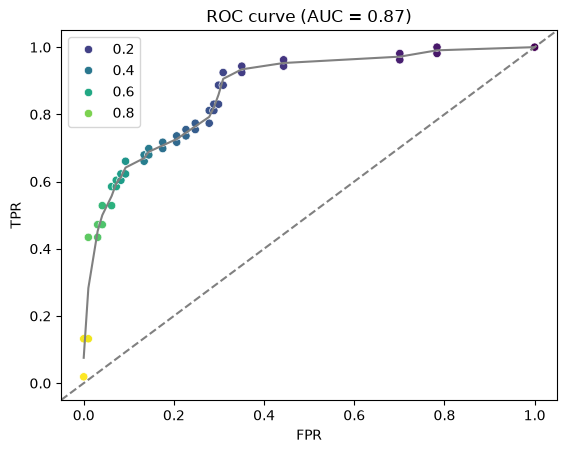

In [54]:
proba = logreg.predict_proba(X_train)[:, 1]
fpr, tpr, thresholds = roc_curve(y_train, proba)
roc = pd.DataFrame({"FPR": fpr, "TPR": tpr, "threshold": thresholds}).iloc[1:]

ax = sns.scatterplot(data=roc, x="FPR", y="TPR", hue="threshold", palette="viridis")
sns.lineplot(data=roc, x="FPR", y="TPR", color="grey", sort=False, errorbar=None, ax=ax)
ax.axline((0, 0), slope=1, ls="--", color="grey")
ax.set_title(f"ROC curve (AUC = {roc_auc_score(y_train, proba):.2f})")

In [ ]:
### Running the model on the test set

In [55]:
test_clean = df_test.copy()
test_clean[zero_as_missing] = test_clean[zero_as_missing].replace(0, np.nan)
test_clean = test_clean.dropna(subset=drop_if_missing)
test_clean = test_clean.fillna(train_medians)      # TRAINING medians, not test medians

X_test = test_clean.drop(columns="Outcome")
y_test = test_clean["Outcome"]

print(f"{len(df_test)} → {len(test_clean)} rows")  # 76 → 75 (one Glucose = 0)


76 → 75 rows


In [ ]:
models = {
    "dummy_random":  dummy_random.predict,
    "dummy_freq":    dummy_freq.predict,
    "logreg (0.5)":  logreg.predict,
    f"logreg ({best_threshold})": logreg_threshold_predict,
}

def scores(predict, X, y):
    pred = predict(X)
    return {
        "recall":    recall_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "f1":        f1_score(y, pred),
        "accuracy":  accuracy_score(y, pred),
    }

results = pd.concat(
    {name: pd.DataFrame({"train": scores(f, X_train, y_train),
                         "test":  scores(f, X_test,  y_test)}).unstack()
     for name, f in models.items()},
    axis=1,
).T.round(2)

results


train                            test                         
             recall precision    f1 accuracy recall precision    f1 accuracy
dummy_random   0.64      0.41  0.50     0.55   0.41      0.29  0.34     0.43
dummy_freq     0.32      0.36  0.34     0.56   0.30      0.33  0.31     0.53
logreg (0.5)   0.66      0.80  0.72     0.82   0.74      0.61  0.67     0.73
logreg (0.2)   0.92      0.60  0.73     0.76   0.93      0.47  0.62     0.60

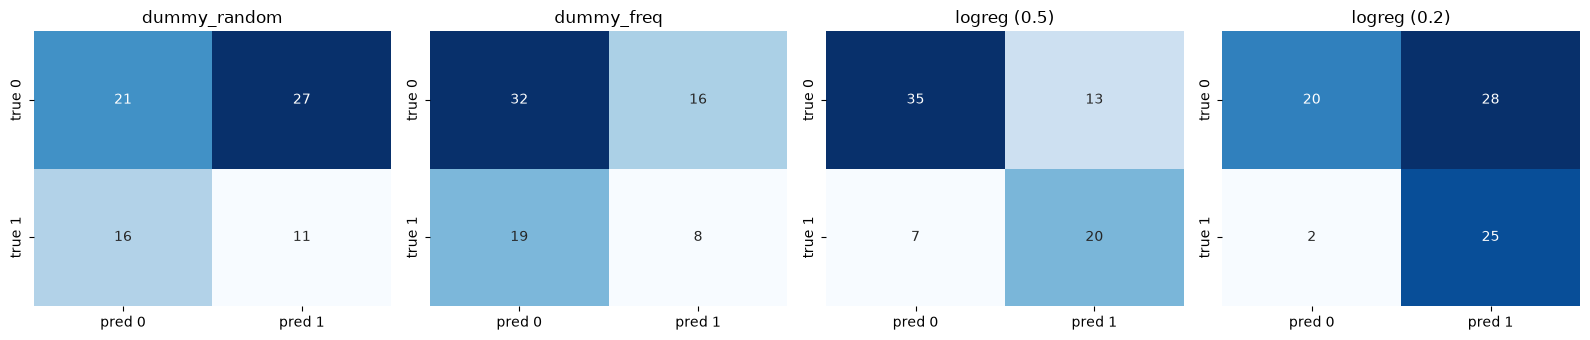

In [59]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.5))
for ax, (name, f) in zip(axes, models.items()):
    sns.heatmap(confusion_matrix(y_test, f(X_test)), annot=True, fmt="d",
                cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
    ax.set_title(name)
plt.tight_layout()
